In [62]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv("../data/Sleep_health_and_lifestyle_dataset.csv",keep_default_na=False)
df.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,None
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,None
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,None
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [63]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    object 
 9   Blood Pressure           374 non-null    object 
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           374 non-null    object 
dtypes: float64(1), int64(7), object(5)
memory usage: 38.1+ KB


,Person ID,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps
count,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000
mean,187.500000,42.184492,7.132086,7.312834,59.171123,5.385027,70.165775,6816.844920
std,108.108742,8.673133,0.795657,1.196956,20.830804,1.774526,4.135676,1617.915679
min,1.000000,27.000000,5.800000,4.000000,30.000000,3.000000,65.000000,3000.000000
25%,94.250000,35.250000,6.400000,6.000000,45.000000,4.000000,68.000000,5600.000000
50%,187.500000,43.000000,7.200000,7.000000,60.000000,5.000000,70.000000,7000.000000
75%,280.750000,50.000000,7.800000,8.000000,75.000000,7.000000,72.000000,8000.000000
max,374.000000,59.000000,8.500000,9.000000,90.000000,8.000000,86.000000,10000.000000


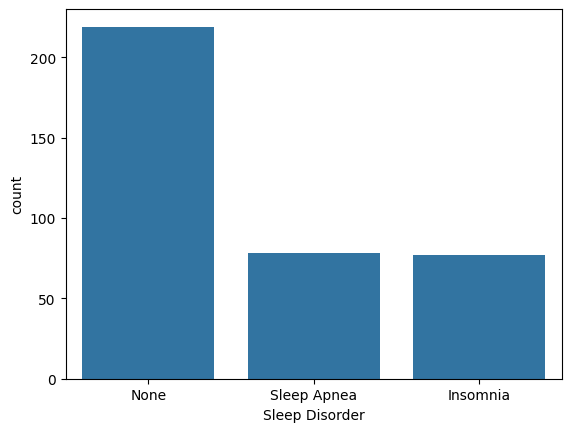

In [64]:
sns.countplot(x='Sleep Disorder',data=df)
plt.savefig("../figures/countplot_sleep_disorder.png",dpi=150,bbox_inches='tight')
plt.show()

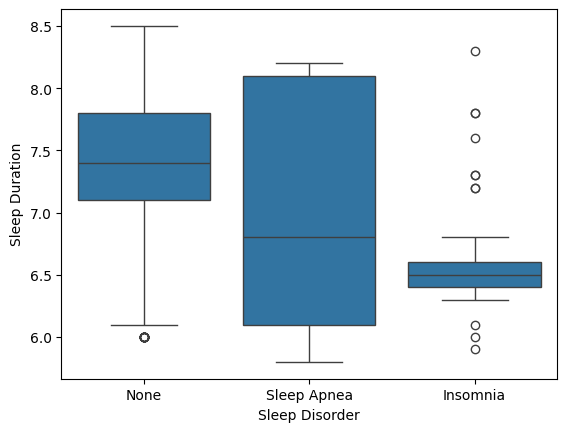

In [65]:
sns.boxplot(x='Sleep Disorder',y='Sleep Duration',data=df)
plt.savefig("../figures/sleep_Durations.png",dpi=150,bbox_inches='tight')

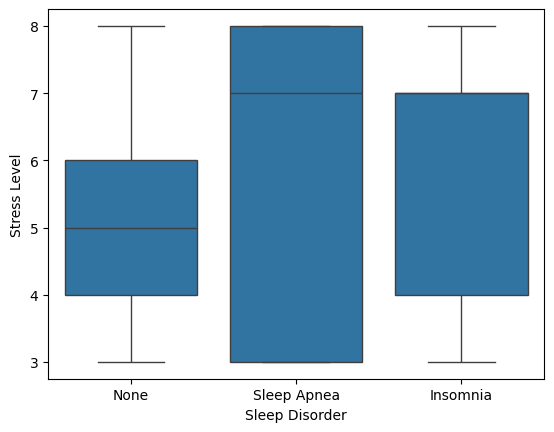

In [66]:
sns.boxplot(x='Sleep Disorder',y='Stress Level',data=df)
plt.savefig("../figures/stress_levels.png",dpi=150,bbox_inches='tight')

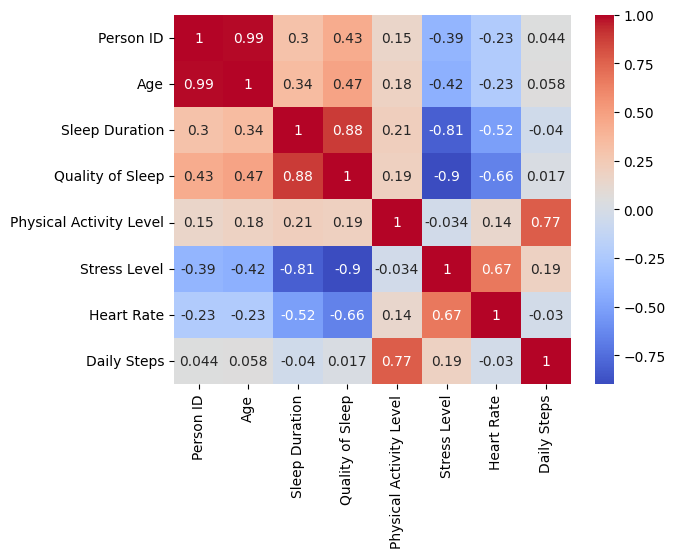

In [67]:
num_df=df.select_dtypes(include ='number')
num_df.corr()
sns.heatmap(num_df.corr(),annot=True,cmap='coolwarm')
plt.savefig("../figures/correlation_heatmap.png",dpi=150,bbox_inches='tight')

In [68]:
df=df.drop(columns=["Person ID"])
df[["Systolic_BP", "Diast35olic_BP"]]=df["Blood Pressure"].str.split("/",expand=True).astype(int)
df=df.drop(columns=["Blood Pressure"])
df["BMI Category"]=df["BMI Category"].replace({"Normal Weight": "Normal"})
print("Rows before:", len(df))
print("Duplicate rows:", df.duplicated().sum())
df.head()

Rows before: 374
Duplicate rows: 242


,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Heart Rate,Daily Steps,Sleep Disorder,Systolic_BP,Diast35olic_BP
0,Male,27,Software Engineer,6.1,6,42,6,Overweight,77,4200,None,126,83
1,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,None,125,80
2,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,None,125,80
3,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140,90
4,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140,90


In [69]:
df = df.drop_duplicates().reset_index(drop=True)
print("Rows after:", len(df))

Rows after: 132


In [70]:
from sklearn.model_selection import train_test_split
x=df.drop(columns=["Sleep Disorder"])
y=df["Sleep Disorder"]
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y,)



In [71]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
num_col=x_train.select_dtypes(include='number').columns.tolist()
cat_col=x_train.select_dtypes(include='object').columns.tolist()
preprocessor=ColumnTransformer(
    transformers=[
        ("num",StandardScaler(),num_col),
        ("cat",OneHotEncoder(handle_unknown="ignore"),cat_col)
    ]
)


In [72]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score
from sklearn.dummy import DummyClassifier

models={
    "Logistic Regression":LogisticRegression(max_iter=1000),
    "Decision Tree":DecisionTreeClassifier(random_state=42),
    "Random Forest":RandomForestClassifier(random_state=42)
}
results=[]
baseline=DummyClassifier(strategy='most_frequent')
baseline.fit(x_train,y_train)

for name,cla in models.items():
    pipe=Pipeline(steps=[
        ("preprocessor",preprocessor),
        ("classifier",cla)
    ])
    cv=cross_val_score(pipe,x_train,y_train,cv=5)
    pipe.fit(x_train,y_train)
    results.append({
        "name":name,
        "mean_cv_score":cv.mean().round(3),
        "cv_std":cv.std().round(3),
        "train_score":pipe.score(x_train,y_train)
    })
results_df=pd.DataFrame(results)
print("Baseline score:",baseline.score(x_test,y_test))
results_df



Baseline score: 0.5555555555555556


,name,mean_cv_score,cv_std,train_score
0,Logistic Regression,0.752,0.082,0.828571
1,Decision Tree,0.533,0.092,0.838095
2,Random Forest,0.629,0.106,0.838095


              precision    recall  f1-score   support

    Insomnia       0.50      0.67      0.57         6
        None       0.80      0.80      0.80        15
 Sleep Apnea       0.75      0.50      0.60         6

    accuracy                           0.70        27
   macro avg       0.68      0.66      0.66        27
weighted avg       0.72      0.70      0.70        27



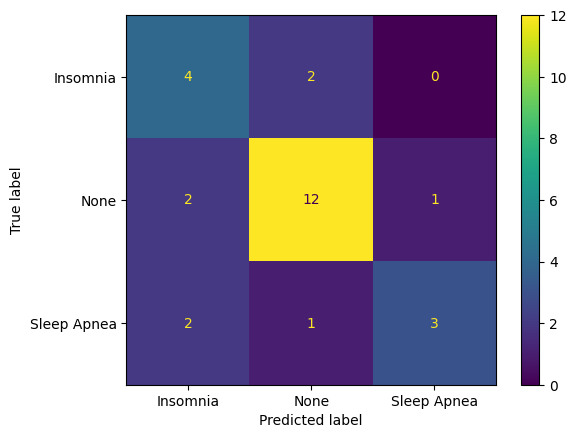

In [73]:
from sklearn.metrics import classification_report,ConfusionMatrixDisplay
best=Pipeline([("preprocessor",preprocessor),("classifier",LogisticRegression(max_iter=1000))])
best.fit(x_train,y_train)
y_pred=best.predict(x_test)
print(classification_report(y_test,y_pred))
ConfusionMatrixDisplay.from_predictions(y_test,y_pred)
plt.savefig("../figures/confusion_matrix.png",dpi=150,bbox_inches='tight')
plt.show()


                             Insomnia      None  Sleep Apnea
cat__Occupation_Accountant   1.017803 -0.646927    -0.370876
cat__Occupation_Teacher      0.377917 -0.800313     0.422396
cat__Occupation_Nurse       -0.790656  0.497702     0.292954
num__Sleep Duration         -0.467511 -0.232747     0.700258
num__Heart Rate             -0.449767 -0.218847     0.668614
num__Quality of Sleep       -0.594422  0.653740    -0.059318
cat__Occupation_Salesperson  0.279940 -0.615733     0.335793
num__Systolic_BP             0.581241 -0.544649    -0.036592


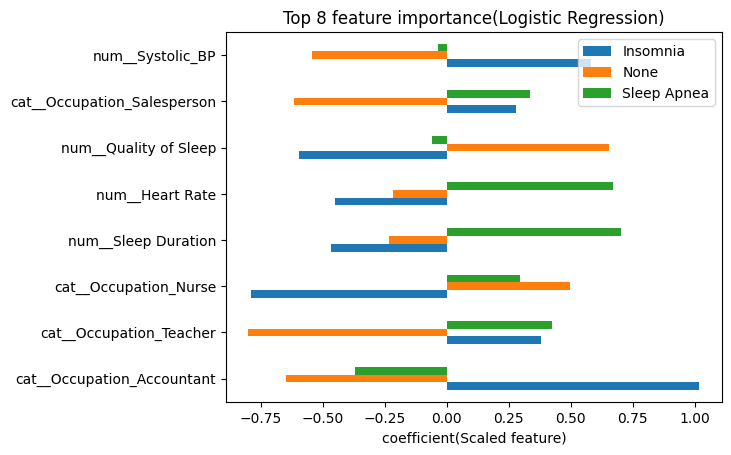

In [74]:
lr=Pipeline([("preprocessor",preprocessor),("classifier",LogisticRegression(max_iter=1000))])
lr.fit(x_train,y_train)
feature_names=lr.named_steps["preprocessor"].get_feature_names_out()
coef=pd.DataFrame(
    lr.named_steps["classifier"].coef_,
    columns=feature_names,
    index=lr.named_steps["classifier"].classes_
).T
coef["strengths"]=coef.abs().max(axis=1)
top=coef.sort_values("strengths",ascending=False).head(8).drop(columns=["strengths"])
print(top)
top.plot(kind="barh",title="Top 8 feature importance(Logistic Regression)")
plt.xlabel("coefficient(Scaled feature)")
plt.savefig("../figures/top_8_feature_importance.png",dpi=150,bbox_inches='tight')
plt.show()

